In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d

import threading
from concurrent.futures import ThreadPoolExecutor

from pyproj import Proj

ROOT = Path().resolve().parents[1]
sys.path.append(str(ROOT / "src"))

from forward import magcal_numba
from forward.thread_func import thread_func

### SC-TLI
L1-L2 penalty in the space domain and structural coupling in the temporal domain

$$
P(\boldsymbol{\beta}) = 
\lambda_s \left( \alpha \left\| \boldsymbol{\beta} \right\|_1 + \frac{1 - \alpha}{2} \| \boldsymbol{\beta} \|_2^2 \right)
+
\lambda_t \sum_{\mathcal{G}_j} \left\| \left( \boldsymbol{D} \boldsymbol{\beta} \right)_{\mathcal{G}_j} \right\|_2
$$

In [2]:
from inversion.SCTLI_with_sens_weight import ADMMGroupLasso

In [3]:
# data misfit
def misfit(f, K, beta):
    return 0.5 * np.linalg.norm(f - K.dot(beta))**2

# penalty
def pen1(beta, alpha):
    return alpha * np.linalg.norm(beta, ord = 1) + (1 - alpha) * 0.5 * np.linalg.norm(beta)**2
    
def pen2(Dbeta, sw, num_of_cells, times):
    
    pen2 = 0
    
    for k in range(num_of_cells):
        temp = 0
        
        for j in range(times-1):
            temp += Dbeta[k + j*num_of_cells]**2
            
        pen2 += sw[k] * np.sqrt(temp)
        
    return pen2

In [4]:
def calcCurvature2(x,y):
    dif_x = np.gradient(x)
    dif_y = np.gradient(y)
    dif2_x = np.gradient(dif_x)
    dif2_y = np.gradient(dif_y)
    curvature = np.abs(dif2_x * dif_y - dif_x * dif2_y) / (dif_x **2 + dif_y **2)**1.5
    return curvature

### Data

In [5]:
# ---------------------------------
# Topography 
# ---------------------------------

df_topo = pd.read_csv("0923_topo_data_fine.csv", )

xtopo = df_topo["xtopo"].values
ytopo = df_topo["ytopo"].values
ztopo = df_topo["ztopo"].values

# 領域設定
xmin, xmax = 530.2, 531.9
ymin, ymax = 4725.6, 4727.3


# ---------------------------------
# 空中磁気探査データ
# ---------------------------------

# --- 2011 --- #
df1 = pd.read_csv("Tar_airmag_w_txye_1sec_2011.txt")

lat1  = df1[' LAT'].values
lon1  = df1[' LON'].values
zobs1 = df1[' EllipsoidHeight'].values * 1e-3
fobs1 = df1[' AIRMAG'].values

# convert latlon to utm (km)
e2u_zone = int(divmod(lon1[0], 6)[0]) + 31
e2u_conv = Proj(proj='utm', zone=e2u_zone, ellps='WGS84')

xobs1, yobs1 = e2u_conv(lon1, lat1)
xobs1 = xobs1 * 1e-3
yobs1 = yobs1 * 1e-3

# 領域指定
mask = [(xmin < xobs1) & (xobs1 < 531.8) & (4725.7 < yobs1) & (yobs1 < 4727.2)][0]
xobs1 = xobs1[mask]
yobs1 = yobs1[mask]
zobs1 = zobs1[mask]
fobs1 = fobs1[mask]


# --- 2012 --- #
df2 = pd.read_csv("Tar_airmag_w_txye_1sec_2012.txt")

lat2  = df2[' LAT'].values
lon2  = df2[' LON'].values
zobs2 = df2[' EllipsoidHeight'].values * 1e-3
fobs2 = df2[' AIRMAG'].values

# convert latlon to utm (km)
xobs2, yobs2 = e2u_conv(lon2, lat2)
xobs2 = xobs2 * 1e-3
yobs2 = yobs2 * 1e-3

# 領域指定
mask = [(xmin < xobs2) & (xobs2 < 531.8) & (4725.7 < yobs2) & (yobs2 < 4727.2)][0]
xobs2 = xobs2[mask]
yobs2 = yobs2[mask]
zobs2 = zobs2[mask]
fobs2 = fobs2[mask]

# 補正
fobs2 += (237 - 3.3) 


# --- 2013 --- #
df3 = pd.read_csv("tar_airmag_w_txye_akgref_1sec_2013.txt")
lat3  = df3[' LAT'].values
lon3  = df3[' LON'].values
zobs3 = df3[' EllipsoidHeight'].values * 1e-3
fobs3 = df3[' AIRMAG'].values

xobs3, yobs3 = e2u_conv(lon3, lat3)
xobs3 = xobs3 * 1e-3
yobs3 = yobs3 * 1e-3

# 補正
fobs3 += (237 - 3.3) 

Text(0, 0.5, 'km')

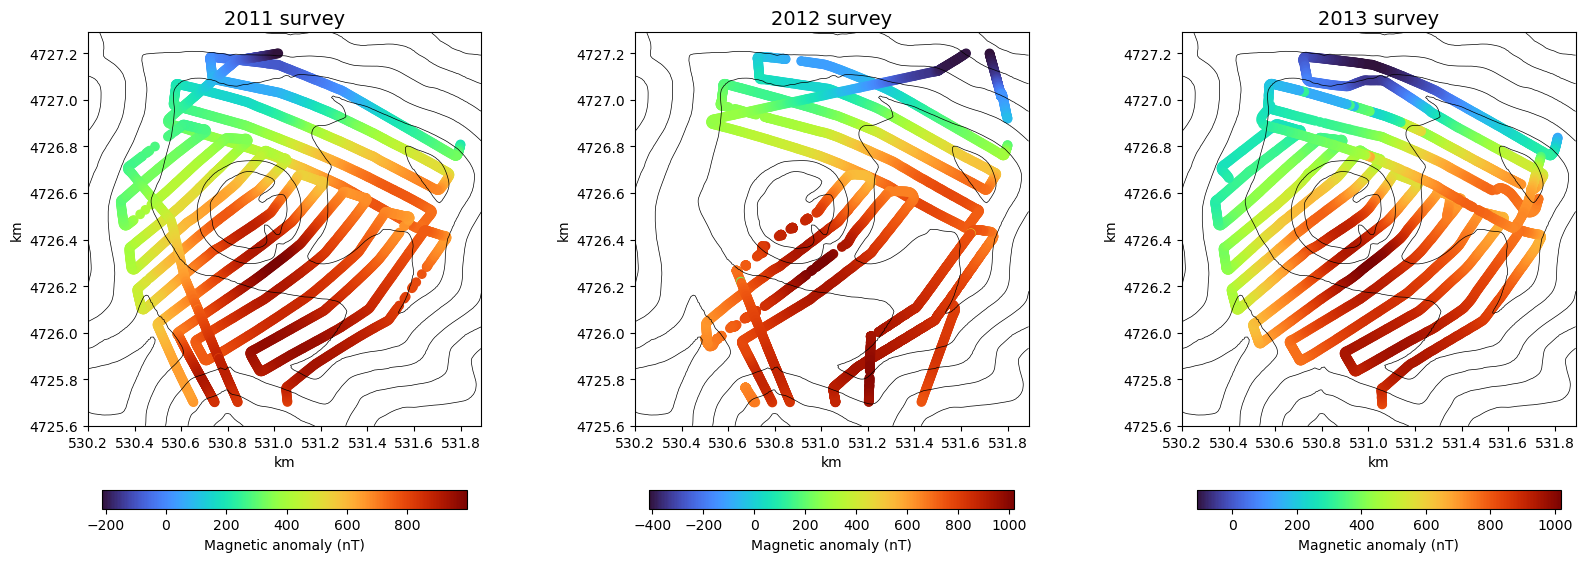

In [6]:
# 図示
fig = plt.figure(figsize = (20, 7))

ax = fig.add_subplot(131)
p = ax.scatter(xobs1, 
               yobs1, 
               c = fobs1, 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2011 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

ax = fig.add_subplot(132)
p = ax.scatter(xobs2, 
               yobs2, 
               c = fobs2, 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2012 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")


ax = fig.add_subplot(133)
p = ax.scatter(xobs3, 
               yobs3, 
               c = fobs3, 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2013 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

In [7]:
# ============================================================
# 2011
# ============================================================

# --- copy ---
xobs1_corr = xobs1.copy()
yobs1_corr = yobs1.copy()
zobs1_corr = zobs1.copy()
fobs1_corr = fobs1.copy()

# --- correction ---
fobs1_corr[[4230, 4310]] += [43.0, 78.0]

# --- indices to remove ---
idx_remove_1 = np.concatenate([
    np.arange(3906, 3911),
    np.arange(1569, 1582),
    np.arange(1992, 1999),
])

# --- mask ---
mask1 = np.ones(len(fobs1_corr), dtype=bool)
mask1[idx_remove_1] = False

# --- apply mask ---
xobs1_corr = xobs1_corr[mask1]
yobs1_corr = yobs1_corr[mask1]
zobs1_corr = zobs1_corr[mask1]
fobs1_corr = fobs1_corr[mask1]


# ============================================================
# 2012
# ============================================================

# --- copy ---
xobs2_corr = xobs2.copy()
yobs2_corr = yobs2.copy()
zobs2_corr = zobs2.copy()
fobs2_corr = fobs2.copy()

# --- correction ---
fobs2_corr[[2361, 2787, 4036]] += [321.5, 321.5, 494.0]

# --- indices to remove ---
idx_remove_2 = np.concatenate([
    np.arange(0, 260),
    np.arange(1490, 1678),
    np.arange(2903, 2970),
    np.arange(3449, 3580),
    np.arange(3900, 4010),
])

# --- mask ---
mask2 = np.ones(len(fobs2_corr), dtype=bool)
mask2[idx_remove_2] = False

# --- apply mask ---
xobs2_corr = xobs2_corr[mask2]
yobs2_corr = yobs2_corr[mask2]
zobs2_corr = zobs2_corr[mask2]
fobs2_corr = fobs2_corr[mask2]

xobs2_corr = np.delete(xobs2_corr, np.arange(2020, 2100))
yobs2_corr = np.delete(yobs2_corr, np.arange(2020, 2100))
zobs2_corr = np.delete(zobs2_corr, np.arange(2020, 2100))
fobs2_corr = np.delete(fobs2_corr, np.arange(2020, 2100))


# ============================================================
# 2013
# ============================================================

# --- copy ---
xobs3_corr = xobs3.copy()
yobs3_corr = yobs3.copy()
zobs3_corr = zobs3.copy()
fobs3_corr = fobs3.copy()

# --- correction ---
fobs3_corr[3304:3326] -= 168
fobs3_corr[3359:3375] -= 168
fobs3_corr[3379:3381] -= 168
fobs3_corr[3425:3429] -= 168

fobs3_corr[3892] -= 20
fobs3_corr[3893:3897] -= 168
fobs3_corr[3897] -= 85

fobs3_corr[3927] -= 10

# ============================================================
# 間引く
# ============================================================
xobs1_corr = xobs1_corr[::20]
yobs1_corr = yobs1_corr[::20]
zobs1_corr = zobs1_corr[::20]
fobs1_corr = fobs1_corr[::20]

xobs2_corr = xobs2_corr[::20]
yobs2_corr = yobs2_corr[::20]
zobs2_corr = zobs2_corr[::20]
fobs2_corr = fobs2_corr[::20]

xobs3_corr = xobs3_corr[::20]
yobs3_corr = yobs3_corr[::20]
zobs3_corr = zobs3_corr[::20]
fobs3_corr = fobs3_corr[::20]

print(fobs1_corr.mean(), fobs2_corr.mean(), fobs3_corr.mean())

567.3269406392694 638.9475647058824 571.07569


Text(0, 0.5, 'km')

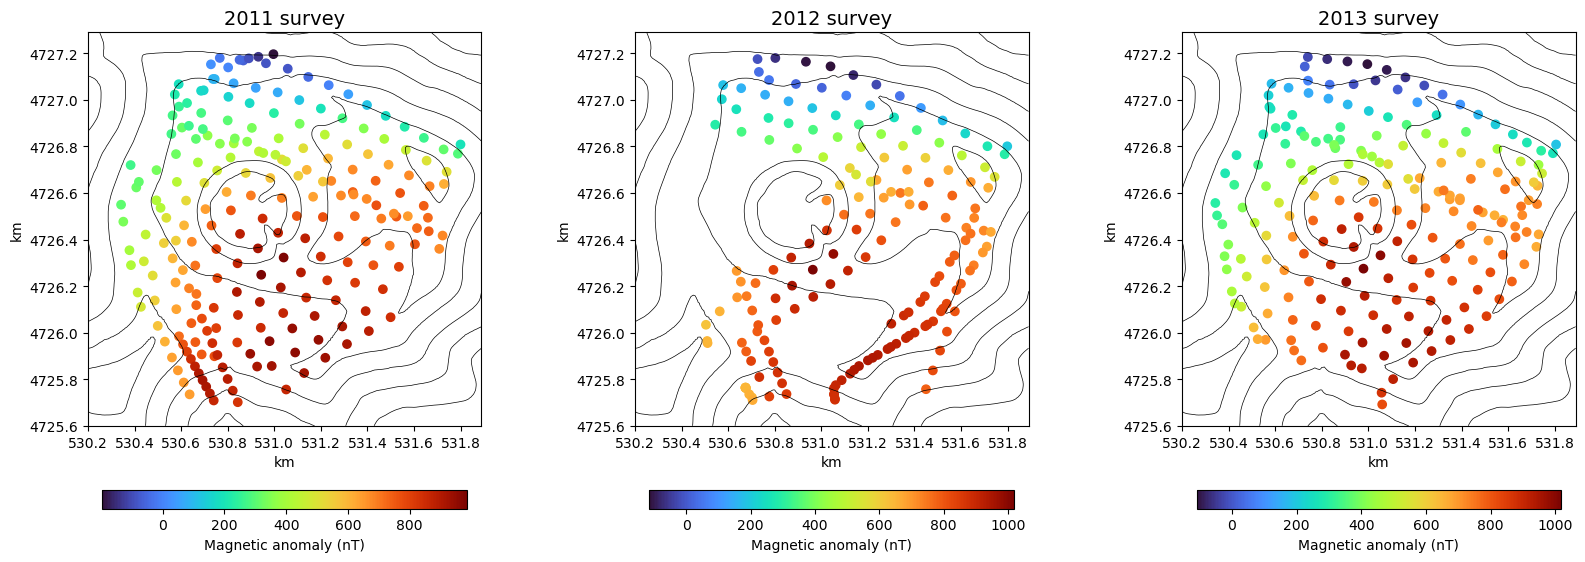

In [8]:
# 図示
fig = plt.figure(figsize = (20, 7))

ax = fig.add_subplot(131)
p = ax.scatter(xobs1_corr, 
               yobs1_corr, 
               c = fobs1_corr, 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2011 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

ax = fig.add_subplot(132)
p = ax.scatter(xobs2_corr, 
               yobs2_corr, 
               c = fobs2_corr, 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2012 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")


ax = fig.add_subplot(133)
p = ax.scatter(xobs3_corr, 
               yobs3_corr, 
               c = fobs3_corr, 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2013 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

Text(0, 0.5, 'km')

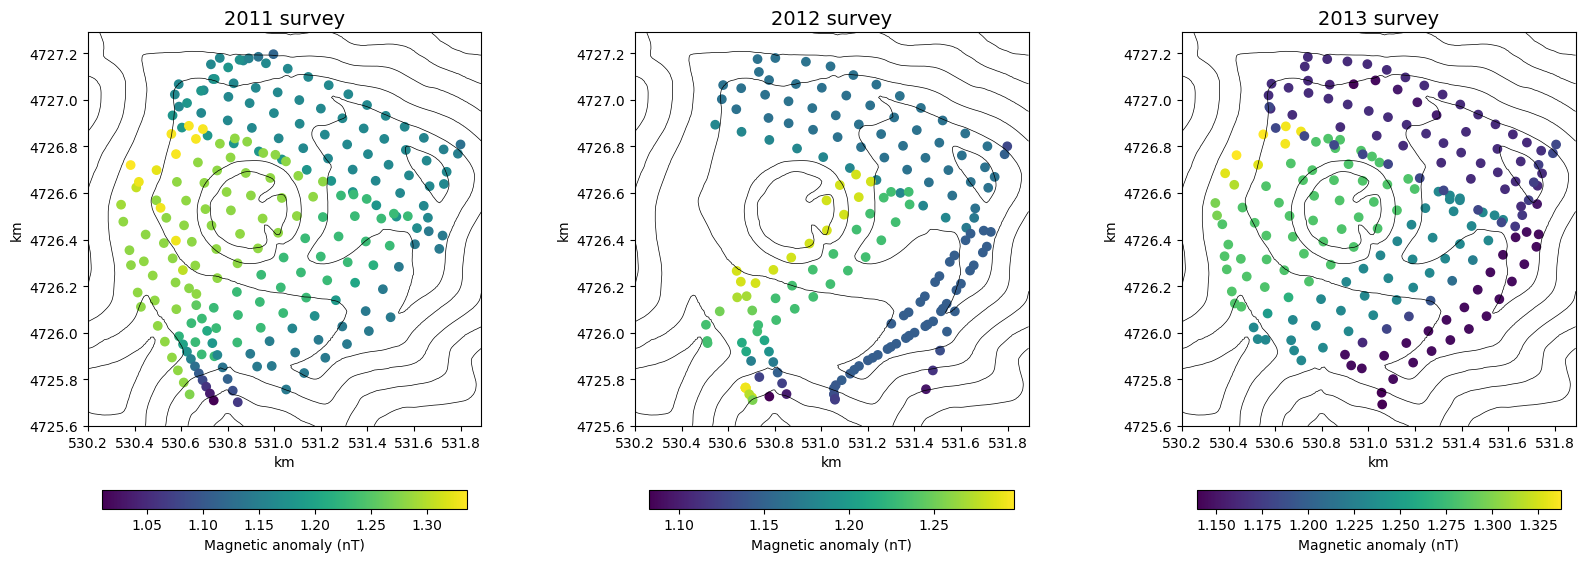

In [9]:
# 図示
fig = plt.figure(figsize = (20, 7))

ax = fig.add_subplot(131)
p = ax.scatter(xobs1_corr, 
               yobs1_corr, 
               c = zobs1_corr, 
               #cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2011 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

ax = fig.add_subplot(132)
p = ax.scatter(xobs2_corr, 
               yobs2_corr, 
               c = zobs2_corr, 
               #cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2012 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")


ax = fig.add_subplot(133)
p = ax.scatter(xobs3_corr, 
               yobs3_corr, 
               c = zobs3_corr, 
               #cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2013 survey", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

### Model domain

In [10]:
### 地下グリッドの作成: xgrd, ygrd, zgrd ###
# incx, incy, incz : x, y, z方向のグリッド間隔
incx = 0.01
incy = 0.01
incz = 0.05

### 地下グリッドの作成: xgrd, ygrd, zgrd ###
nx = len(np.unique(xtopo))
ny = len(np.unique(ytopo))
nz = 20
[yy2, zz2, xx2] = np.meshgrid(np.unique(ytopo), np.zeros(nz), np.unique(xtopo))

for k in range(nz):
    for i in range(nx):
        for j in range(ny):
            zz2[k, j, i] = ztopo[i + nx*j] - 0.5*incz - incz*k
            
xgrd = xx2.reshape(-1)
ygrd = yy2.reshape(-1)
zgrd = zz2.reshape(-1)

# 図示用
xfig, yfig, zfig = [], [], []

for i in range(len(xgrd)):
    j = i // (nx*ny)
    
    # 各グリッドの8頂点の座標を格納
    xfig.append([xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, 
                 xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx])
    yfig.append([ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy, 
                 ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy])
    zfig.append([zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, 
                 zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz])

# array化
xfig = np.array(xfig)
yfig = np.array(yfig)
zfig = np.array(zfig)

#dim: ブロックのサイズ
dim = [[incx / 2., incx / 2.], [incy / 2., incy / 2.], [incz / 2., incz / 2.]]

# 偏角(度)
dec = -9.1
# 伏角(度)
inc = 57.1

print("nx = {}, ny = {}, nz = {}, m = {}".format(nx, ny, nz, nx * ny * nz))

nx = 170, ny = 170, nz = 20, m = 578000


### Kernel matrix

In [11]:
from numba import njit, prange

@njit(parallel=True, fastmath=True)
def kernel_matrix2(
    exf,
    mgz,
    xobs,
    yobs,
    zobs,
    xgrd,
    ygrd,
    zgrd,
    dim,
    L
):

    nobs  = xobs.shape[0]
    ncell = xgrd.shape[0]

    xmin = np.min(xgrd)
    xmax = np.max(xgrd)

    ymin = np.min(ygrd)
    ymax = np.max(ygrd)

    K = np.zeros((nobs, ncell))

    for s in prange(ncell):

        dx1 = dim[0,0]
        dx2 = dim[0,1]

        dy1 = dim[1,0]
        dy2 = dim[1,1]

        dz1 = dim[2,0]
        dz2 = dim[2,1]

        if abs(xgrd[s] - xmin) < 1e-10:
            dx1 += L
        elif abs(xgrd[s] - xmax) < 1e-10:
            dx2 += L

        if abs(ygrd[s] - ymin) < 1e-10:
            dy1 += L
        elif abs(ygrd[s] - ymax) < 1e-10:
            dy2 += L

        dim_new = np.empty((3,2))

        dim_new[0,0] = dx1
        dim_new[0,1] = dx2

        dim_new[1,0] = dy1
        dim_new[1,1] = dy2

        dim_new[2,0] = dz1
        dim_new[2,1] = dz2

        h = magcal_numba.prism(
            mgz,
            xobs,
            yobs,
            zobs,
            xgrd[s],
            ygrd[s],
            zgrd[s],
            dim_new
        )

        K[:,s] = magcal_numba.total_force(exf, h)

        if s%1000 == 0: 
            print(s) 

    return K

In [12]:
%%time
# num of threads
from numba import set_num_threads, get_num_threads
set_num_threads(12)
print(get_num_threads())

# Unit vector creation
mgz = magcal_numba.di2xyz(dec = dec, inc = inc)
exf = mgz.copy()

# Kernel matrix
K1 = kernel_matrix2(
     exf,
     mgz,
     xobs1_corr.astype(np.float64),
     yobs1_corr.astype(np.float64),
     zobs1_corr.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

# Kernel matrix
K2 = kernel_matrix2(
     exf,
     mgz,
     xobs2_corr.astype(np.float64),
     yobs2_corr.astype(np.float64),
     zobs2_corr.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

# Kernel matrix
K3 = kernel_matrix2(
     exf,
     mgz,
     xobs3_corr.astype(np.float64),
     yobs3_corr.astype(np.float64),
     zobs3_corr.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

12
0
530000
241000
193000
482000
434000145000

386000
97000
338000
49000
290000
1000
242000
531000
194000
483000
435000
146000
387000
98000
339000
50000
291000
2000
243000
532000
195000
484000
436000
147000
388000
99000
340000
51000
292000
3000
244000
533000
196000
485000
437000148000

389000
100000
341000
52000
293000
4000
245000
534000
197000
486000
438000
149000
390000
101000
342000
294000
53000
246000
5000
535000
487000
198000
150000439000

391000
343000
102000
295000
54000
247000
6000
536000
488000
199000
440000151000

392000
344000
103000
296000
55000
248000
7000
537000
489000
200000
441000152000

393000
345000
104000
297000
56000
249000
8000
490000
538000
201000
442000
153000
394000
346000
105000
298000
250000
57000
9000
491000
539000
202000
443000
154000
395000
347000
106000
299000
251000
58000
492000
540000
10000
203000
444000
155000
396000
348000
107000
300000
252000
59000
493000
541000
204000
11000
445000
156000
397000
349000
301000
253000
108000
60000
494000
542000
205000
1

### Coarsening

In [13]:
# ============================================================
# Coarsening
# ============================================================

coarsen = 5

# ------------------------------------------------------------
# Grid size
# ------------------------------------------------------------

if nx % coarsen != 0 or ny % coarsen != 0:
    raise ValueError(
        f"nx={nx}, ny={ny} must be divisible by {coarsen}"
    )

nxc = nx // coarsen
nyc = ny // coarsen

print(f"Fine grid   : {nx} x {ny} x {nz}")
print(f"Coarse grid : {nxc} x {nyc} x {nz}")


# ------------------------------------------------------------
# x, y, z grids
# ------------------------------------------------------------

x3 = xgrd.reshape(nz, ny, nx)
y3 = ygrd.reshape(nz, ny, nx)
z3 = zgrd.reshape(nz, ny, nx)

xgrd_coarse_3d = (
    x3.reshape(nz, nyc, coarsen, nxc, coarsen)
      .mean(axis=(2, 4))
)

ygrd_coarse_3d = (
    y3.reshape(nz, nyc, coarsen, nxc, coarsen)
      .mean(axis=(2, 4))
)

zgrd_coarse_3d = (
    z3.reshape(nz, nyc, coarsen, nxc, coarsen)
      .mean(axis=(2, 4))
)

xgrd_coarse = xgrd_coarse_3d.reshape(-1)
ygrd_coarse = ygrd_coarse_3d.reshape(-1)
zgrd_coarse = zgrd_coarse_3d.reshape(-1)


# ------------------------------------------------------------
# Kernel matrix
# ------------------------------------------------------------

K1_4d = K1.reshape(
    K1.shape[0],
    nz,
    ny,
    nx
)
K2_4d = K2.reshape(
    K2.shape[0],
    nz,
    ny,
    nx
)
K3_4d = K3.reshape(
    K3.shape[0],
    nz,
    ny,
    nx
)

# 5 x 5 fine cells -> 1 coarse cell
# Sum the kernels of 25 fine cells
K1_coarse_4d = (
    K1_4d
    .reshape(
        K1.shape[0],
        nz,
        nyc,
        coarsen,
        nxc,
        coarsen
    )
    .sum(axis=(3, 5))
)
K2_coarse_4d = (
    K2_4d
    .reshape(
        K2.shape[0],
        nz,
        nyc,
        coarsen,
        nxc,
        coarsen
    )
    .sum(axis=(3, 5))
)
K3_coarse_4d = (
    K3_4d
    .reshape(
        K3.shape[0],
        nz,
        nyc,
        coarsen,
        nxc,
        coarsen
    )
    .sum(axis=(3, 5))
)

K1_coarse = K1_coarse_4d.reshape(
    K1.shape[0],
    nz * nyc * nxc
)
K2_coarse = K2_coarse_4d.reshape(
    K2.shape[0],
    nz * nyc * nxc
)
K3_coarse = K3_coarse_4d.reshape(
    K3.shape[0],
    nz * nyc * nxc
)

# ------------------------------------------------------------
# Check
# ------------------------------------------------------------

print("xgrd       :", xgrd.shape)
print("xgrd_coarse:", xgrd_coarse.shape)

print("K1         :", K1.shape)
print("K1_coarse  :", K1_coarse.shape)

print("K2         :", K2.shape)
print("K2_coarse  :", K2_coarse.shape)

print("K3         :", K3.shape)
print("K3_coarse  :", K3_coarse.shape)

Fine grid   : 170 x 170 x 20
Coarse grid : 34 x 34 x 20
xgrd       : (578000,)
xgrd_coarse: (23120,)
K1         : (219, 578000)
K1_coarse  : (219, 23120)
K2         : (170, 578000)
K2_coarse  : (170, 23120)
K3         : (200, 578000)
K3_coarse  : (200, 23120)


In [14]:
# Depth weighting
w1_coarse = np.linalg.norm(K1_coarse, axis=0)
X1_coarse = K1_coarse / w1_coarse

w2_coarse = np.linalg.norm(K2_coarse, axis=0)
X2_coarse = K2_coarse / w2_coarse

w3_coarse = np.linalg.norm(K3_coarse, axis=0)
X3_coarse = K3_coarse / w3_coarse

### Joint Inversion

In [15]:
# Z
Z = np.r_[np.c_[X1_coarse, np.zeros(X1_coarse.shape), np.zeros(X1_coarse.shape)], 
          np.c_[np.zeros(X2_coarse.shape), X2_coarse, np.zeros(X2_coarse.shape)],
          np.c_[np.zeros(X3_coarse.shape), np.zeros(X3_coarse.shape), X3_coarse],]

# Hoshimoto et al. (2014): 5.3 A/m
b_mean = 5.3

# fobs
fobs1_mean = fobs1_corr - K1.dot(b_mean * np.ones(K1.shape[1]))
fobs2_mean = fobs2_corr - K2.dot(b_mean * np.ones(K2.shape[1]))
fobs3_mean = fobs3_corr - K3.dot(b_mean * np.ones(K3.shape[1]))

fobs = np.r_[fobs1_mean, fobs2_mean, fobs3_mean]
print(fobs.mean(), fobs1_mean.mean(), fobs2_mean.mean(), fobs3_mean.mean())

# centerization  # 全体で中心化
fobs = fobs - fobs.mean()

# D
zeros = sp.sparse.diags(np.zeros(len(xgrd_coarse)))
D = sp.sparse.vstack([sp.sparse.hstack([-sp.sparse.diags(1 / w1_coarse), sp.sparse.diags(1 / w2_coarse), zeros]), 
                      sp.sparse.hstack([zeros, -sp.sparse.diags(1 / w2_coarse), sp.sparse.diags(1 / w3_coarse)]),
                     ])

# Sensitivity parameter
sw = np.power(w1_coarse * w2_coarse * w3_coarse, 1/3)

print(Z.shape, fobs.shape, D.shape, sw.shape)

423.0168294371769 435.30837893941066 417.7634447175491 414.02295974391456
(589, 69360) (589,) (46240, 69360) (23120,)


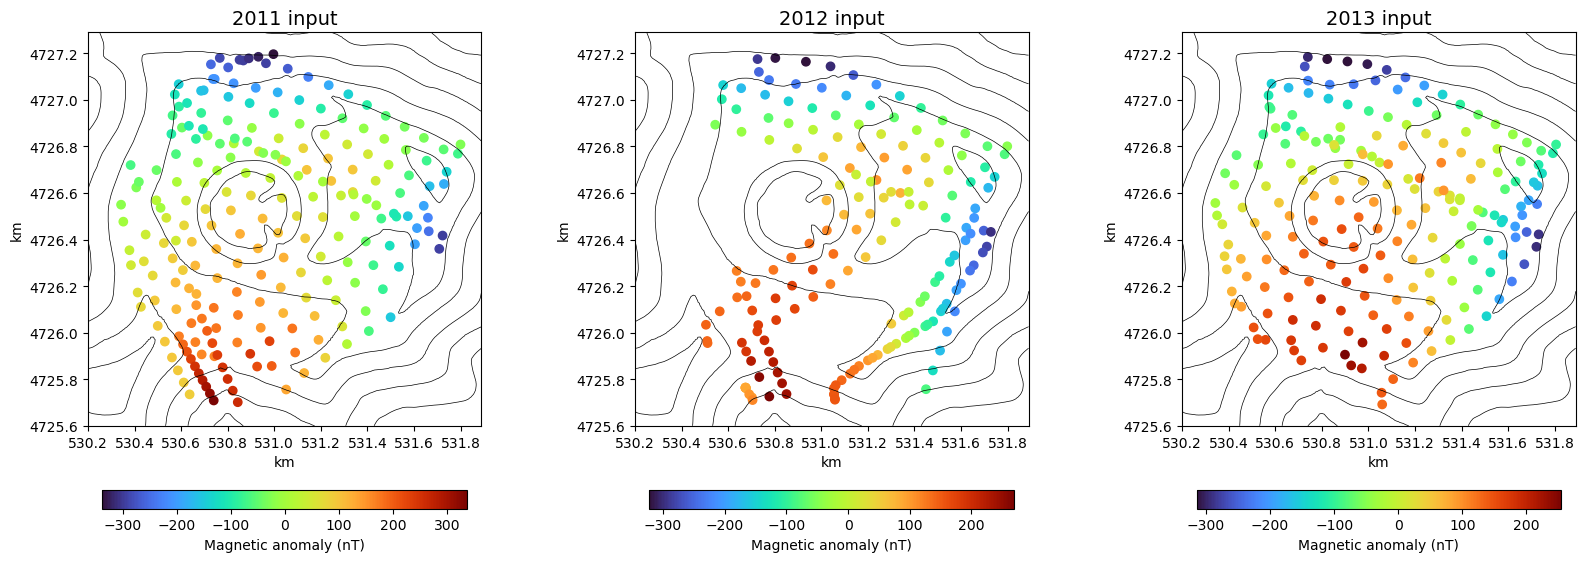

In [55]:
# 図示
fig = plt.figure(figsize = (20, 7))

ax = fig.add_subplot(131)
p = ax.scatter(xobs1_corr, 
               yobs1_corr, 
               c = fobs[:len(fobs1_mean)], 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2011 input", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

ax = fig.add_subplot(132)
p = ax.scatter(xobs2_corr, 
               yobs2_corr, 
               c = fobs[len(fobs1_mean):len(fobs1_mean)+len(fobs2_mean)],
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2012 input", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")


ax = fig.add_subplot(133)
p = ax.scatter(xobs3_corr, 
               yobs3_corr, 
               c = fobs[len(fobs1_mean)+len(fobs2_mean):],
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)

ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)

ax.set_aspect("equal")
ax.set_title("2013 input", fontsize = 14)

#ax.set_xlim(xtopo.min(), xtopo.max())
#ax.set_ylim(ytopo.min(), ytopo.max())
ax.set_xlabel("km")
ax.set_ylabel("km")

plt.savefig("1006_input_data-3.png", dpi = 600, bbox_inches = "tight")

In [16]:
%%time
# parameter
rho = 1.0
eta = 1.0

# inverse matrix
inv1 = sp.sparse.linalg.inv(rho * sp.sparse.eye(Z.shape[1]) + eta * D.T @ D)
inv2 = np.linalg.inv(np.eye(Z.shape[0]) + Z @ (inv1 @ Z.T))

C:\Users\ri710\anaconda3\envs\pygmt\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:603: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
C:\Users\ri710\anaconda3\envs\pygmt\Lib\site-packages\scipy\sparse\linalg\_matfuncs.py:76: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  Ainv = spsolve(A, I)


CPU times: total: 13min 47s
Wall time: 14min 5s


### Step1

In [17]:
# hyper-parameters
lams_s = np.power(10., np.arange(-1.0, 2.1, 0.25))
print("lams_s = {}".format(lams_s))

lam_t = 1.0  # fixed

lams_s = [  0.1          0.17782794   0.31622777   0.56234133   1.
   1.77827941   3.16227766   5.62341325  10.          17.7827941
  31.6227766   56.23413252 100.        ]


In [18]:
# L1-L2 ratio
alpha = 0.76

In [19]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []

for lis in range(len(lams_s)):

    params_all.append([lams_s[lis], lam_t])
    print("lm1 = {}, lm2 = {}".format(lams_s[lis], lam_t))

    model = ADMMGroupLasso(lambda_s = lams_s[lis], 
                           lambda_t = lam_t, 
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3)
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 3, 
              num_of_cells = X1_coarse.shape[1]
             )
    
    beta_sim1 = model.beta_[0*X1_coarse.shape[1]:1*X1_coarse.shape[1]] / w1_coarse
    beta_sim2 = model.beta_[1*X1_coarse.shape[1]:2*X1_coarse.shape[1]] / w2_coarse
    beta_sim3 = model.beta_[2*X1_coarse.shape[1]:3*X1_coarse.shape[1]] / w3_coarse

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)

lm1 = 0.1, lm2 = 1.0
iter = 0, delta_s = 0.6480500045542986, delta_t = 0.12935088278090046, delta = 0.6480500045542986
iter = 1000, delta_s = 3.330657717778836e-05, delta_t = 0.007356823399884144, delta = 0.007356823399884144
iter = 2000, delta_s = 9.654682859851425e-06, delta_t = 0.0049497038149579455, delta = 0.0049497038149579455
iter = 13000, delta_s = 6.766691841847247e-07, delta_t = 0.0017376564656999157, delta = 0.0017376564656999157
iter = 14000, delta_s = 6.358872626061407e-07, delta_t = 0.0016483365097193308, delta = 0.0016483365097193308
iter = 15000, delta_s = 5.735074296959591e-07, delta_t = 0.0015965494517710798, delta = 0.0015965494517710798
iter = 16000, delta_s = 5.464700944339206e-07, delta_t = 0.0015092413107137144, delta = 0.0015092413107137144
iter = 17000, delta_s = 5.1165345030983e-07, delta_t = 0.0014375308262824687, delta = 0.0014375308262824687
iter = 18000, delta_s = 4.948214546652988e-07, delta_t = 0.0013823231985744782, delta = 0.0013823231985744782
iter = 

In [20]:
import pickle
with open('1006_Params_new_4d-3-1.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1006_Betas1_new_4d-3-1.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1006_Betas2_new_4d-3-1.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1006_Betas3_new_4d-3-1.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)

In [21]:
# L-curve
rss2_1 = []
nrm2_1 = []

for lis in range(len(lams_s)):
    
    betas_temp = np.r_[betas1_all[lis]*w1_coarse, betas2_all[lis]*w2_coarse, betas3_all[lis]*w3_coarse]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen1(betas_temp, alpha = alpha)
    
    rss2_1.append(rss_temp)
    nrm2_1.append(pen_temp)

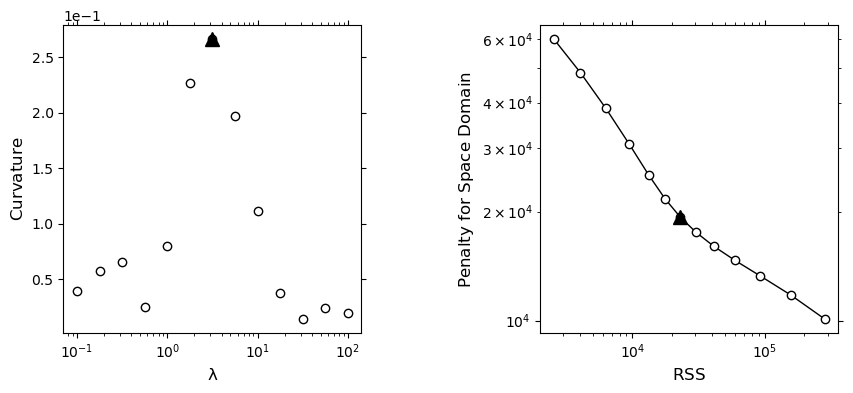

In [22]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_s, calcCurvature2(np.log(rss2_1), np.log(nrm2_1)), "o", ms=6, color='#000000',markerfacecolor='#ffffff', linewidth = 1)

num_opt_1 = np.argmax(calcCurvature2(np.log(rss2_1), np.log(nrm2_1)))

ax.semilogx(lams_s[num_opt_1], calcCurvature2(np.log(rss2_1), np.log(nrm2_1))[num_opt_1], '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
ax.ticklabel_format(style="sci",  axis="y", scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.5, 6.5)

ax = fig.add_subplot(122)
ax.loglog(rss2_1, nrm2_1, 'o-', ms=6, color='#000000', markerfacecolor='#ffffff', linewidth = 1)
ax.loglog(rss2_1[num_opt_1], nrm2_1[num_opt_1], '^', ms=10, color = "black")
ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Space Domain}$', fontsize = 12)
#ax.set_xlim(1e3, 13e4)
#ax.set_ylim(2e3, 3e4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

plt.subplots_adjust(wspace=0.6)

In [23]:
print("optimal lambda_s = {:.2f}".format(lams_s[num_opt_1]))

optimal lambda_s = 3.16


### Step.2

In [24]:
# hyper-parameters
lams_t = np.power(10., np.arange(-1.0, 2.1, 0.25))
print("lams_t = {}".format(lams_t))

lams_t = [  0.1          0.17782794   0.31622777   0.56234133   1.
   1.77827941   3.16227766   5.62341325  10.          17.7827941
  31.6227766   56.23413252 100.        ]


In [25]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []

for lit in range(len(lams_t)):

    params_all.append([lams_s[num_opt_1], lams_t[lit]])
    print("lm1 = {}, lm2 = {}".format(lams_s[num_opt_1], lams_t[lit]))

    model = ADMMGroupLasso(lambda_s = lams_s[num_opt_1], 
                           lambda_t = lams_t[lit],
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3)
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 3, 
              num_of_cells = X1_coarse.shape[1]
             )
    
    beta_sim1 = model.beta_[0*X1_coarse.shape[1]:1*X1_coarse.shape[1]] / w1_coarse
    beta_sim2 = model.beta_[1*X1_coarse.shape[1]:2*X1_coarse.shape[1]] / w2_coarse
    beta_sim3 = model.beta_[2*X1_coarse.shape[1]:3*X1_coarse.shape[1]] / w3_coarse

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)

lm1 = 3.1622776601683795, lm2 = 0.1
iter = 0, delta_s = 0.684372506264162, delta_t = 0.30246199964101567, delta = 0.684372506264162
iter = 1000, delta_s = 2.5332339208702852e-06, delta_t = 0.001409360053083642, delta = 0.001409360053083642
Converged at iteration 1268
lm1 = 3.1622776601683795, lm2 = 0.1778279410038923
iter = 0, delta_s = 0.684372506264162, delta_t = 0.26022132318120517, delta = 0.684372506264162
Converged at iteration 627
lm1 = 3.1622776601683795, lm2 = 0.31622776601683794
iter = 0, delta_s = 0.684372506264162, delta_t = 0.2031970630461363, delta = 0.684372506264162
Converged at iteration 413
lm1 = 3.1622776601683795, lm2 = 0.5623413251903491
iter = 0, delta_s = 0.684372506264162, delta_t = 0.13842274579998445, delta = 0.684372506264162
Converged at iteration 368
lm1 = 3.1622776601683795, lm2 = 1.0
iter = 0, delta_s = 0.684372506264162, delta_t = 0.12935088278090046, delta = 0.684372506264162
Converged at iteration 390
lm1 = 3.1622776601683795, lm2 = 1.7782794100389228


In [26]:
import pickle
with open('1006_Params_new_4d-3-2.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1006_Betas1_new_4d-3-2.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1006_Betas2_new_4d-3-2.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1006_Betas3_new_4d-3-2.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)

In [27]:
# L-curve
rss2_2 = []
nrm2_2 = []

for lit in range(len(lams_t)):
    
    betas_temp = np.r_[betas1_all[lit]*w1_coarse, betas2_all[lit]*w2_coarse, betas3_all[lit]*w3_coarse]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen2(D @ betas_temp, sw, X1_coarse.shape[1], 3)
    
    rss2_2.append(rss_temp)
    nrm2_2.append(pen_temp)
    print(rss_temp, pen_temp)

22405.895548411543 4135.082680442772
22493.076446429965 3453.9630605722673
22622.68801469523 2782.0479671416033
22803.333710003702 2154.9616874306744
23061.430872791414 1589.5973009556437
23499.789677775425 1067.411819399687
24113.281039206064 682.3529145543852
24817.138742187402 454.2359995395414
25651.495345646745 313.5551653779136
27024.587582745065 202.5004032884893
29152.394437847848 113.33467381770762
30888.286778023732 73.82576067866924
31778.67085263588 58.9664409789848


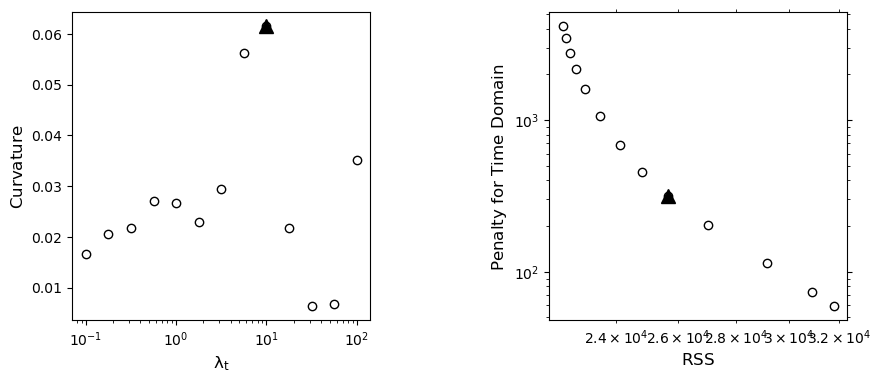

In [28]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_t, calcCurvature2(np.log(rss2_2), np.log(nrm2_2)), 
            "o", ms=6, color='k',markerfacecolor='#ffffff', linewidth = 1)

num_opt_2 = np.argmax(calcCurvature2(np.log(rss2_2), np.log(nrm2_2)))

ax.semilogx(lams_t[num_opt_2], 
            calcCurvature2(np.log(rss2_2), np.log(nrm2_2))[num_opt_2], 
            '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda_t}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

#ax.xaxis.set_ticks_position('both')
#ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
#ax.ticklabel_format(style="sci",  axis="y",scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.1, 0.65)

ax = fig.add_subplot(122)
ax.loglog(rss2_2, nrm2_2, 'o', ms=6, color='k', markerfacecolor='#ffffff', linewidth = 1)

ax.loglog(rss2_2[num_opt_2], 
          nrm2_2[num_opt_2], 
          '^', ms=10, color = "black")

ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Time Domain}$', fontsize = 12)
#ax.set_xlim(3.16e4, 3.23e4)
#ax.set_ylim(6e1, 5e2)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.6)
#ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
#ax.ticklabel_format(style="sci",  axis="y",scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.1, 0.65)

#ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.6)

In [29]:
print("optimal lambda_t = {}".format(lams_t[num_opt_2]))

optimal lambda_t = 10.0


#### 一旦図示 

In [30]:
# 最適モデル
beta1_coarse = betas1_all[num_opt_2] + b_mean
beta2_coarse = betas2_all[num_opt_2] + b_mean
beta3_coarse = betas3_all[num_opt_2] + b_mean

# coarse modelを3次元化
beta1_coarse_3d = beta1_coarse.reshape(
    nz, nyc, nxc
)
beta2_coarse_3d = beta2_coarse.reshape(
    nz, nyc, nxc
)
beta3_coarse_3d = beta3_coarse.reshape(
    nz, nyc, nxc
)

# 5 x 5 に展開
beta1_fine_3d = np.repeat(
    np.repeat(beta1_coarse_3d, coarsen, axis=1),
    coarsen,
    axis=2
)
beta2_fine_3d = np.repeat(
    np.repeat(beta2_coarse_3d, coarsen, axis=1),
    coarsen,
    axis=2
)
beta3_fine_3d = np.repeat(
    np.repeat(beta3_coarse_3d, coarsen, axis=1),
    coarsen,
    axis=2
)

# 1次元化
beta1 = beta1_fine_3d.reshape(-1)
beta2 = beta2_fine_3d.reshape(-1)
beta3 = beta3_fine_3d.reshape(-1)

In [31]:
# 断面を取る場所
x_slice = 530.9
y_slice = 4726.6
z_slice = 0.5

# 図示範囲
#xmin, xmax = xtopo.min(), xtopo.max()
#ymin, ymax = ytopo.min(), ytopo.max()
xlim = (530.4, 531.6)
ylim = (4725.9, 4727.1)
zlim = (0.2, 1.2)

CPU times: total: 1min 57s
Wall time: 1min 59s


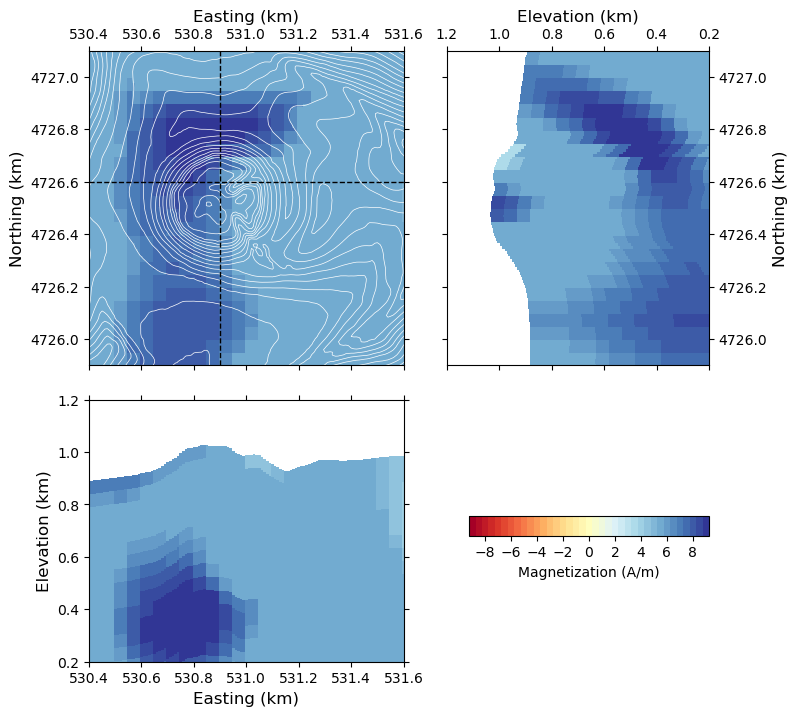

In [38]:
%%time
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

# Colormap
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-9.25, 9.26, 0.5)
cmap = plt.get_cmap("RdYlBu")
norm = BoundaryNorm(bounds, cmap.N)

# 図示
fig = plt.figure(figsize=(8, 8))

# グリッドスペック
gs = gridspec.GridSpec(2, 2, 
                       width_ratios  = [(xlim[1] - xlim[0]) / (zlim[1] - zlim[0]), 1], 
                       height_ratios = [(ylim[1] - ylim[0]) / (zlim[1] - zlim[0]), 1])
gs.update(wspace=0.15, hspace=0.1)

# 地形・水平断面図
ax1 = fig.add_subplot(gs[0, 0]) # 左上
#ax1.set_facecolor('lightgrey')
cs = ax1.contour(xtopo.reshape(ny, nx), ytopo.reshape(ny, nx), (ztopo*1e3).reshape(ny, nx), 
                 colors = "white", linewidths = 0.5, 
                 levels = np.arange(0, 1500, 10),
                )
# 断面
for i in range(len(xgrd)):
    
    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # 条件
    if (z_min - 1e-5 <= z_slice) & (z_slice <= z_max + 1e-5):
        
        # 直方体の縦横
        width  = x_max - x_min
        height = y_max - y_min

        # beta_forward の値に応じて色を取得
        beta_val = beta1[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, y_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax1.add_patch(rect)


ax1.set_xlabel("Easting (km)", fontsize = 12)
ax1.set_ylabel("Northing (km)", fontsize = 12)
ax1.set_aspect("equal")
#ax1.set_title("z = {:.2f} km".format(z_slice))
ax1.set_xlim(xlim)
ax1.set_ylim(ylim)
#ax1.set_xticks([677.0, 677.5, 678.0])
#ax1.set_yticks([4808.5, 4809, 4809.5, 4810])
ax1.xaxis.set_ticks_position('top')
ax1.xaxis.set_label_position('top')
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# 観測点
#ax1.scatter(xobs1_new, yobs1_new, s = 1, color = "white",)

# 断面を取る場所
ax1.plot(np.arange(xlim[0], xlim[1]+1, 0.1), y_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)
ax1.plot(x_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)


# 東西断面図
ax2 = fig.add_subplot(gs[1, 0])  # 左下
#ax2.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    # 条件
    if (y_min <= y_slice) & (y_slice <= y_max):
        
        # 直方体
        width  = x_max - x_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta1[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, z_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax2.add_patch(rect)

# 断面を取る場所
#ax2.plot(np.arange(xlim[0], xlim[1]+1, 0.1), z_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)

ax2.set_xlabel("Easting (km)", fontsize = 12)
ax2.set_ylabel("Elevation (km)", fontsize = 12)
ax2.set_aspect("equal")
ax2.set_xlim(xlim)
ax2.set_ylim(zlim)
#ax2.set_xticks([677.0, 677.5, 678.0])
#ax2.set_yticks([0.5, 1.0, 1.5, 2.0])
#ax2.set_title("y = {:.2f} km".format(y_slice))
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')

# 南北断面図
ax3 = fig.add_subplot(gs[0, 1]) # 右上
#ax3.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    if (x_min <= x_slice) & (x_slice <= x_max):

        # 直方体
        width  = y_max - y_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta1[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((z_min, y_min), height, width, facecolor=color, edgecolor='white', linewidth=0.0)
        ax3.add_patch(rect)

        
# 断面を取る場所
#ax3.plot(z_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)

ax3.set_ylabel("Northing (km)", fontsize = 12)
ax3.set_xlabel("Elevation (km)", fontsize = 12)
ax3.set_aspect("equal")
ax3.set_ylim(ylim)
ax3.set_xlim(zlim)
#ax3.set_yticks([4808.5, 4809, 4809.5, 4810])
#ax3.set_xticks([1.0, 1.5])
#ax3.set_title("x = {:.2f} km".format(x_slice))
ax3.invert_xaxis()
ax3.xaxis.set_ticks_position('top')
ax3.xaxis.set_label_position('top')
ax3.yaxis.set_ticks_position('right')
ax3.yaxis.set_label_position('right')
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')

# カラーバー
cx = fig.add_axes([0.60, 0.27, 0.3, 0.025])
cb = clb.ColorbarBase(ax=cx, norm=norm, orientation='horizontal', 
                      cmap=cmap, label='Magnetization (A/m)', 
                      ticks = [-8, -6, -4, -2, 0, 2, 4, 6, 8])
cb.ax.minorticks_off()

# 深さ表示
#ax1.text(634.27, 4810.05, "{:.1f} km BSL".format(z_slice), backgroundcolor="white", fontsize = 12, alpha = 1, 
#         bbox={"facecolor" : "white", "edgecolor" : "k", "boxstyle" : "Square", "linewidth" : 0}, 
#         #weight='bold', 
#         zorder=20)

plt.savefig("1006_tarumae_2011_results-3.png", dpi = 600, bbox_inches = "tight")

CPU times: total: 2min 10s
Wall time: 2min 13s


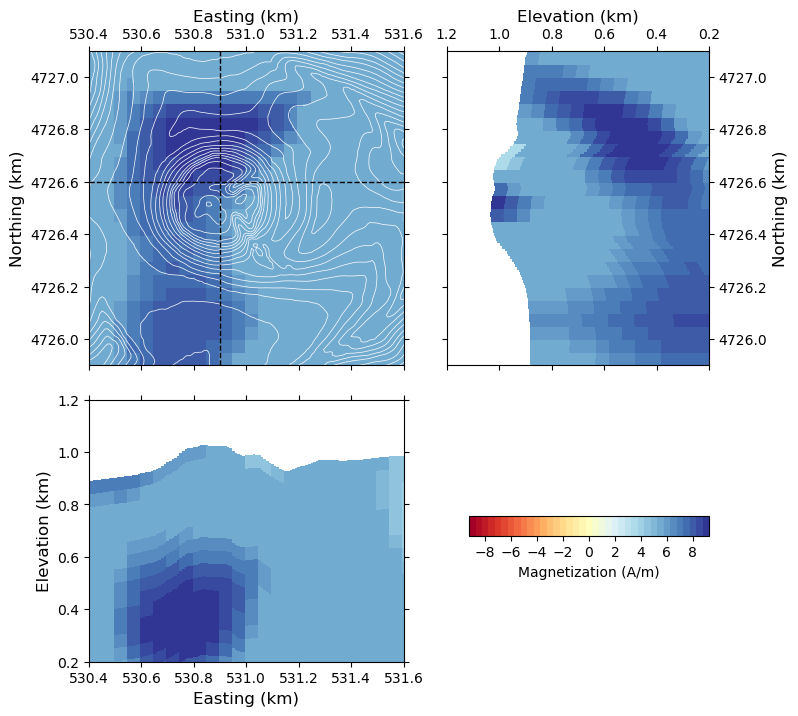

In [56]:
%%time
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

# Colormap
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-9.25, 9.26, 0.5)
cmap = plt.get_cmap("RdYlBu")
norm = BoundaryNorm(bounds, cmap.N)

# 図示
fig = plt.figure(figsize=(8, 8))

# グリッドスペック
gs = gridspec.GridSpec(2, 2, 
                       width_ratios  = [(xlim[1] - xlim[0]) / (zlim[1] - zlim[0]), 1], 
                       height_ratios = [(ylim[1] - ylim[0]) / (zlim[1] - zlim[0]), 1])
gs.update(wspace=0.15, hspace=0.1)

# 地形・水平断面図
ax1 = fig.add_subplot(gs[0, 0]) # 左上
#ax1.set_facecolor('lightgrey')
cs = ax1.contour(xtopo.reshape(ny, nx), ytopo.reshape(ny, nx), (ztopo*1e3).reshape(ny, nx), 
                 colors = "white", linewidths = 0.5, 
                 levels = np.arange(0, 1500, 10),
                )
# 断面
for i in range(len(xgrd)):
    
    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # 条件
    if (z_min - 1e-5 <= z_slice) & (z_slice <= z_max + 1e-5):
        
        # 直方体の縦横
        width  = x_max - x_min
        height = y_max - y_min

        # beta_forward の値に応じて色を取得
        beta_val = beta2[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, y_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax1.add_patch(rect)


ax1.set_xlabel("Easting (km)", fontsize = 12)
ax1.set_ylabel("Northing (km)", fontsize = 12)
ax1.set_aspect("equal")
#ax1.set_title("z = {:.2f} km".format(z_slice))
ax1.set_xlim(xlim)
ax1.set_ylim(ylim)
#ax1.set_xticks([677.0, 677.5, 678.0])
#ax1.set_yticks([4808.5, 4809, 4809.5, 4810])
ax1.xaxis.set_ticks_position('top')
ax1.xaxis.set_label_position('top')
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# 観測点
#ax1.scatter(xobs1_new, yobs1_new, s = 1, color = "white",)

# 断面を取る場所
ax1.plot(np.arange(xlim[0], xlim[1]+1, 0.1), y_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)
ax1.plot(x_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)


# 東西断面図
ax2 = fig.add_subplot(gs[1, 0])  # 左下
#ax2.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    # 条件
    if (y_min <= y_slice) & (y_slice <= y_max):
        
        # 直方体
        width  = x_max - x_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta2[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, z_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax2.add_patch(rect)

# 断面を取る場所
#ax2.plot(np.arange(xlim[0], xlim[1]+1, 0.1), z_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)

ax2.set_xlabel("Easting (km)", fontsize = 12)
ax2.set_ylabel("Elevation (km)", fontsize = 12)
ax2.set_aspect("equal")
ax2.set_xlim(xlim)
ax2.set_ylim(zlim)
#ax2.set_xticks([677.0, 677.5, 678.0])
#ax2.set_yticks([0.5, 1.0, 1.5, 2.0])
#ax2.set_title("y = {:.2f} km".format(y_slice))
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')

# 南北断面図
ax3 = fig.add_subplot(gs[0, 1]) # 右上
#ax3.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    if (x_min <= x_slice) & (x_slice <= x_max):

        # 直方体
        width  = y_max - y_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta2[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((z_min, y_min), height, width, facecolor=color, edgecolor='white', linewidth=0.0)
        ax3.add_patch(rect)

        
# 断面を取る場所
#ax3.plot(z_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)

ax3.set_ylabel("Northing (km)", fontsize = 12)
ax3.set_xlabel("Elevation (km)", fontsize = 12)
ax3.set_aspect("equal")
ax3.set_ylim(ylim)
ax3.set_xlim(zlim)
#ax3.set_yticks([4808.5, 4809, 4809.5, 4810])
#ax3.set_xticks([1.0, 1.5])
#ax3.set_title("x = {:.2f} km".format(x_slice))
ax3.invert_xaxis()
ax3.xaxis.set_ticks_position('top')
ax3.xaxis.set_label_position('top')
ax3.yaxis.set_ticks_position('right')
ax3.yaxis.set_label_position('right')
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')

# カラーバー
cx = fig.add_axes([0.60, 0.27, 0.3, 0.025])
cb = clb.ColorbarBase(ax=cx, norm=norm, orientation='horizontal', 
                      cmap=cmap, label='Magnetization (A/m)', 
                      ticks = [-8, -6, -4, -2, 0, 2, 4, 6, 8])
cb.ax.minorticks_off()

# 深さ表示
#ax1.text(634.27, 4810.05, "{:.1f} km BSL".format(z_slice), backgroundcolor="white", fontsize = 12, alpha = 1, 
#         bbox={"facecolor" : "white", "edgecolor" : "k", "boxstyle" : "Square", "linewidth" : 0}, 
#         #weight='bold', 
#         zorder=20)

plt.savefig("1006_tarumae_2012_results-3.png", dpi = 600, bbox_inches = "tight")

CPU times: total: 2min 15s
Wall time: 2min 18s


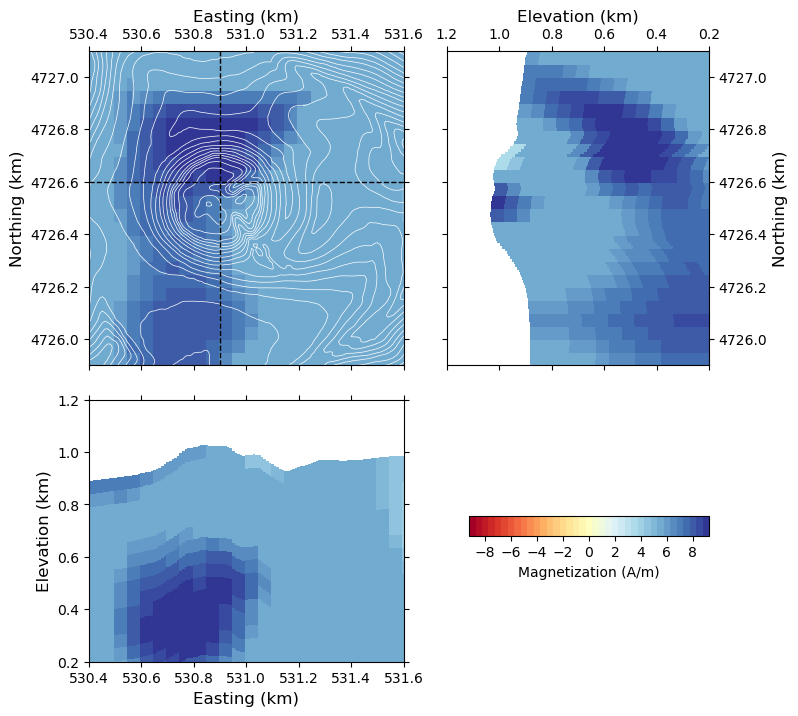

In [44]:
%%time
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

# Colormap
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-9.25, 9.26, 0.5)
cmap = plt.get_cmap("RdYlBu")
norm = BoundaryNorm(bounds, cmap.N)

# 図示
fig = plt.figure(figsize=(8, 8))

# グリッドスペック
gs = gridspec.GridSpec(2, 2, 
                       width_ratios  = [(xlim[1] - xlim[0]) / (zlim[1] - zlim[0]), 1], 
                       height_ratios = [(ylim[1] - ylim[0]) / (zlim[1] - zlim[0]), 1])
gs.update(wspace=0.15, hspace=0.1)

# 地形・水平断面図
ax1 = fig.add_subplot(gs[0, 0]) # 左上
#ax1.set_facecolor('lightgrey')
cs = ax1.contour(xtopo.reshape(ny, nx), ytopo.reshape(ny, nx), (ztopo*1e3).reshape(ny, nx), 
                 colors = "white", linewidths = 0.5, 
                 levels = np.arange(0, 1500, 10),
                )
# 断面
for i in range(len(xgrd)):
    
    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # 条件
    if (z_min - 1e-5 <= z_slice) & (z_slice <= z_max + 1e-5):
        
        # 直方体の縦横
        width  = x_max - x_min
        height = y_max - y_min

        # beta_forward の値に応じて色を取得
        beta_val = beta3[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, y_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax1.add_patch(rect)


ax1.set_xlabel("Easting (km)", fontsize = 12)
ax1.set_ylabel("Northing (km)", fontsize = 12)
ax1.set_aspect("equal")
#ax1.set_title("z = {:.2f} km".format(z_slice))
ax1.set_xlim(xlim)
ax1.set_ylim(ylim)
#ax1.set_xticks([677.0, 677.5, 678.0])
#ax1.set_yticks([4808.5, 4809, 4809.5, 4810])
ax1.xaxis.set_ticks_position('top')
ax1.xaxis.set_label_position('top')
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# 観測点
#ax1.scatter(xobs1_new, yobs1_new, s = 1, color = "white",)

# 断面を取る場所
ax1.plot(np.arange(xlim[0], xlim[1]+1, 0.1), y_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)
ax1.plot(x_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)


# 東西断面図
ax2 = fig.add_subplot(gs[1, 0])  # 左下
#ax2.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    # 条件
    if (y_min <= y_slice) & (y_slice <= y_max):
        
        # 直方体
        width  = x_max - x_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta3[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, z_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax2.add_patch(rect)

# 断面を取る場所
#ax2.plot(np.arange(xlim[0], xlim[1]+1, 0.1), z_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)

ax2.set_xlabel("Easting (km)", fontsize = 12)
ax2.set_ylabel("Elevation (km)", fontsize = 12)
ax2.set_aspect("equal")
ax2.set_xlim(xlim)
ax2.set_ylim(zlim)
#ax2.set_xticks([677.0, 677.5, 678.0])
#ax2.set_yticks([0.5, 1.0, 1.5, 2.0])
#ax2.set_title("y = {:.2f} km".format(y_slice))
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')

# 南北断面図
ax3 = fig.add_subplot(gs[0, 1]) # 右上
#ax3.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    if (x_min <= x_slice) & (x_slice <= x_max):

        # 直方体
        width  = y_max - y_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta3[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((z_min, y_min), height, width, facecolor=color, edgecolor='white', linewidth=0.0)
        ax3.add_patch(rect)

        
# 断面を取る場所
#ax3.plot(z_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)

ax3.set_ylabel("Northing (km)", fontsize = 12)
ax3.set_xlabel("Elevation (km)", fontsize = 12)
ax3.set_aspect("equal")
ax3.set_ylim(ylim)
ax3.set_xlim(zlim)
#ax3.set_yticks([4808.5, 4809, 4809.5, 4810])
#ax3.set_xticks([1.0, 1.5])
#ax3.set_title("x = {:.2f} km".format(x_slice))
ax3.invert_xaxis()
ax3.xaxis.set_ticks_position('top')
ax3.xaxis.set_label_position('top')
ax3.yaxis.set_ticks_position('right')
ax3.yaxis.set_label_position('right')
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')

# カラーバー
cx = fig.add_axes([0.60, 0.27, 0.3, 0.025])
cb = clb.ColorbarBase(ax=cx, norm=norm, orientation='horizontal', 
                      cmap=cmap, label='Magnetization (A/m)', 
                      ticks = [-8, -6, -4, -2, 0, 2, 4, 6, 8])
cb.ax.minorticks_off()

# 深さ表示
#ax1.text(634.27, 4810.05, "{:.1f} km BSL".format(z_slice), backgroundcolor="white", fontsize = 12, alpha = 1, 
#         bbox={"facecolor" : "white", "edgecolor" : "k", "boxstyle" : "Square", "linewidth" : 0}, 
#         #weight='bold', 
#         zorder=20)

plt.savefig("1006_tarumae_2013_results-3.png", dpi = 600, bbox_inches = "tight")

CPU times: total: 1min 51s
Wall time: 1min 54s


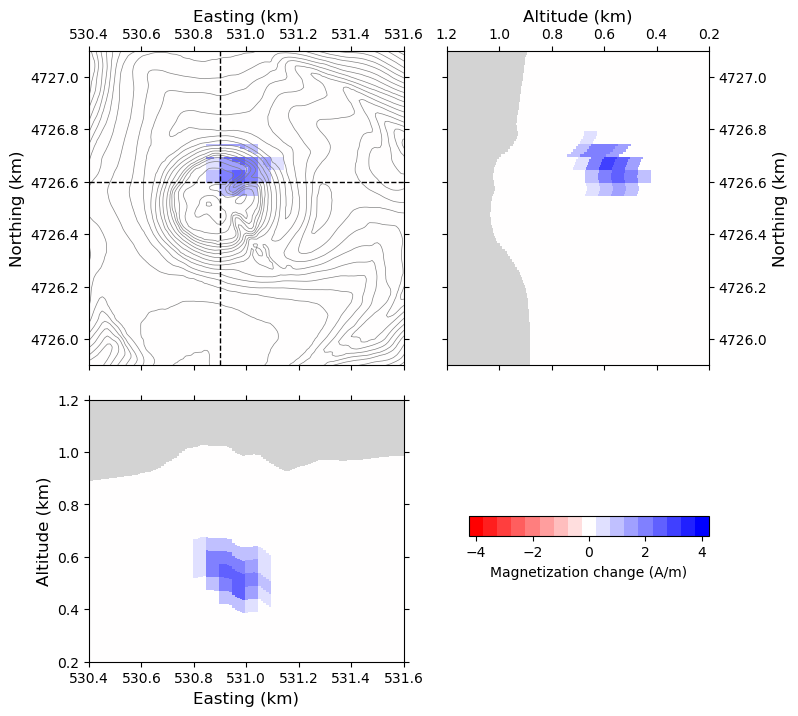

In [41]:
%%time
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

# Colormap
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("bwr_r")
norm = BoundaryNorm(bounds, cmap.N)

# 図示
fig = plt.figure(figsize=(8, 8))

# グリッドスペック
gs = gridspec.GridSpec(2, 2, 
                       width_ratios  = [(xlim[1] - xlim[0]) / (zlim[1] - zlim[0]), 1], 
                       height_ratios = [(ylim[1] - ylim[0]) / (zlim[1] - zlim[0]), 1])
gs.update(wspace=0.15, hspace=0.1)

# 地形・水平断面図
ax1 = fig.add_subplot(gs[0, 0]) # 左上
ax1.set_facecolor('lightgrey')
cs = ax1.contour(xtopo.reshape(ny, nx), ytopo.reshape(ny, nx), (ztopo*1e3).reshape(ny, nx), 
                 colors = "gray", linewidths = 0.5, 
                 levels = np.arange(0, 1500, 10),
                )
# 断面
for i in range(len(xgrd)):
    
    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # 条件
    if (z_min - 1e-5 <= z_slice) & (z_slice <= z_max + 1e-5):
        
        # 直方体の縦横
        width  = x_max - x_min
        height = y_max - y_min

        # beta_forward の値に応じて色を取得
        beta_val = beta2[i] - beta1[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, y_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax1.add_patch(rect)


ax1.set_xlabel("Easting (km)", fontsize = 12)
ax1.set_ylabel("Northing (km)", fontsize = 12)
ax1.set_aspect("equal")
#ax1.set_title("z = {:.2f} km".format(z_slice))
ax1.set_xlim(xlim)
ax1.set_ylim(ylim)
#ax1.set_xticks([677.0, 677.5, 678.0])
#ax1.set_yticks([3531.0, 3531.5, 3532.0, 3532.5])
ax1.xaxis.set_ticks_position('top')
ax1.xaxis.set_label_position('top')
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# 観測点
#ax1.scatter(xobs1_new, yobs1_new, s = 1, color = "white",)

# 断面を取る場所
ax1.plot(np.arange(xlim[0], xlim[1]+1, 0.1), y_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)
ax1.plot(x_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)


# 東西断面図
ax2 = fig.add_subplot(gs[1, 0])  # 左下
ax2.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    # 条件
    if (y_min <= y_slice) & (y_slice <= y_max):
        
        # 直方体
        width  = x_max - x_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta2[i] - beta1[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, z_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax2.add_patch(rect)

# 断面を取る場所
#ax2.plot(np.arange(xlim[0], xlim[1]+1, 0.1), z_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)

ax2.set_xlabel("Easting (km)", fontsize = 12)
ax2.set_ylabel("Altitude (km)", fontsize = 12)
ax2.set_aspect("equal")
ax2.set_xlim(xlim)
ax2.set_ylim(zlim)
#ax2.set_xticks([677.0, 677.5, 678.0])
#ax2.set_yticks([1.0, 1.5])
#ax2.set_title("y = {:.2f} km".format(y_slice))
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')

# 南北断面図
ax3 = fig.add_subplot(gs[0, 1]) # 右上
ax3.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    if (x_min <= x_slice) & (x_slice <= x_max):

        # 直方体
        width  = y_max - y_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta2[i] - beta1[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((z_min, y_min), height, width, facecolor=color, edgecolor='white', linewidth=0.0)
        ax3.add_patch(rect)

        
# 断面を取る場所
#ax3.plot(z_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)

ax3.set_ylabel("Northing (km)", fontsize = 12)
ax3.set_xlabel("Altitude (km)", fontsize = 12)
ax3.set_aspect("equal")
ax3.set_ylim(ylim)
ax3.set_xlim(zlim)
#ax3.set_yticks([3531.0, 3531.5, 3532.0, 3532.5])
#ax3.set_xticks([1.0, 1.5])
#ax3.set_title("x = {:.2f} km".format(x_slice))
ax3.invert_xaxis()
ax3.xaxis.set_ticks_position('top')
ax3.xaxis.set_label_position('top')
ax3.yaxis.set_ticks_position('right')
ax3.yaxis.set_label_position('right')
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')

# カラーバー
cx = fig.add_axes([0.60, 0.27, 0.3, 0.025])
cb = clb.ColorbarBase(ax=cx, norm=norm, orientation='horizontal', 
                      cmap=cmap, label='Magnetization change (A/m)', 
                      ticks = [-8, -6, -4, -2, 0, 2, 4, 6, 8])
cb.ax.minorticks_off()

plt.savefig("1006_tarumae_2012-2011_results-3.png", dpi = 600, bbox_inches = "tight")

CPU times: total: 1min 52s
Wall time: 1min 55s


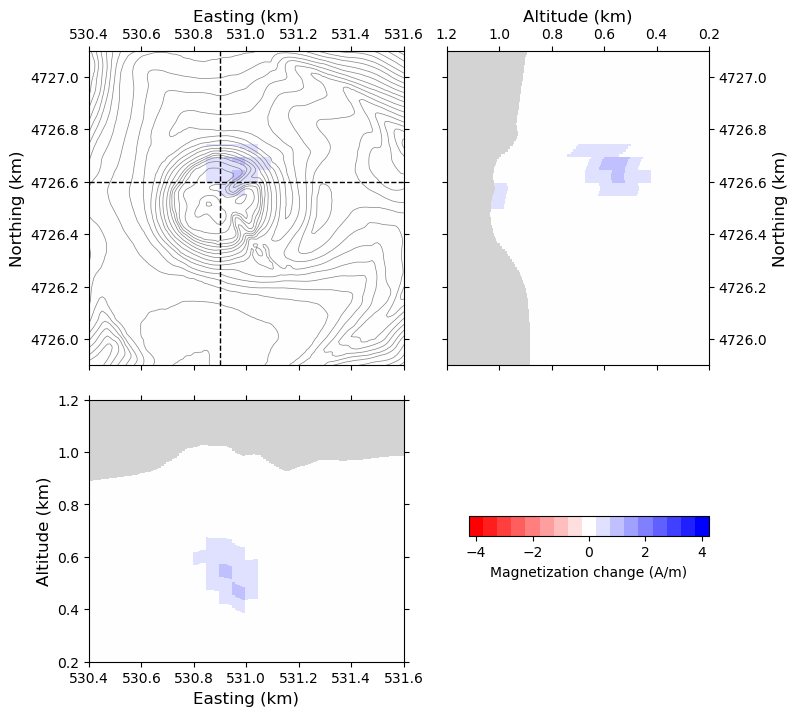

In [42]:
%%time
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

# Colormap
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("bwr_r")
norm = BoundaryNorm(bounds, cmap.N)

# 図示
fig = plt.figure(figsize=(8, 8))

# グリッドスペック
gs = gridspec.GridSpec(2, 2, 
                       width_ratios  = [(xlim[1] - xlim[0]) / (zlim[1] - zlim[0]), 1], 
                       height_ratios = [(ylim[1] - ylim[0]) / (zlim[1] - zlim[0]), 1])
gs.update(wspace=0.15, hspace=0.1)

# 地形・水平断面図
ax1 = fig.add_subplot(gs[0, 0]) # 左上
ax1.set_facecolor('lightgrey')
cs = ax1.contour(xtopo.reshape(ny, nx), ytopo.reshape(ny, nx), (ztopo*1e3).reshape(ny, nx), 
                 colors = "gray", linewidths = 0.5, 
                 levels = np.arange(0, 1500, 10),
                )
# 断面
for i in range(len(xgrd)):
    
    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # 条件
    if (z_min - 1e-5 <= z_slice) & (z_slice <= z_max + 1e-5):
        
        # 直方体の縦横
        width  = x_max - x_min
        height = y_max - y_min

        # beta_forward の値に応じて色を取得
        beta_val = beta3[i] - beta2[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, y_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax1.add_patch(rect)


ax1.set_xlabel("Easting (km)", fontsize = 12)
ax1.set_ylabel("Northing (km)", fontsize = 12)
ax1.set_aspect("equal")
#ax1.set_title("z = {:.2f} km".format(z_slice))
ax1.set_xlim(xlim)
ax1.set_ylim(ylim)
#ax1.set_xticks([677.0, 677.5, 678.0])
#ax1.set_yticks([3531.0, 3531.5, 3532.0, 3532.5])
ax1.xaxis.set_ticks_position('top')
ax1.xaxis.set_label_position('top')
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# 観測点
#ax1.scatter(xobs1_new, yobs1_new, s = 1, color = "white",)

# 断面を取る場所
ax1.plot(np.arange(xlim[0], xlim[1]+1, 0.1), y_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)
ax1.plot(x_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)


# 東西断面図
ax2 = fig.add_subplot(gs[1, 0])  # 左下
ax2.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    # 条件
    if (y_min <= y_slice) & (y_slice <= y_max):
        
        # 直方体
        width  = x_max - x_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta3[i] - beta2[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((x_min, z_min), width, height, facecolor=color, edgecolor='white', linewidth=0.0)
        ax2.add_patch(rect)

# 断面を取る場所
#ax2.plot(np.arange(xlim[0], xlim[1]+1, 0.1), z_slice * np.ones(len(np.arange(xlim[0], xlim[1]+1, 0.1))), "--", color = "k", linewidth = 1)

ax2.set_xlabel("Easting (km)", fontsize = 12)
ax2.set_ylabel("Altitude (km)", fontsize = 12)
ax2.set_aspect("equal")
ax2.set_xlim(xlim)
ax2.set_ylim(zlim)
#ax2.set_xticks([677.0, 677.5, 678.0])
#ax2.set_yticks([1.0, 1.5])
#ax2.set_title("y = {:.2f} km".format(y_slice))
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')

# 南北断面図
ax3 = fig.add_subplot(gs[0, 1]) # 右上
ax3.set_facecolor('lightgrey')

# 断面
for i in range(len(xgrd)):

    # 座標
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)

    if (x_min <= x_slice) & (x_slice <= x_max):

        # 直方体
        width  = y_max - y_min
        height = z_max - z_min

        # beta_forward の値に応じて色を取得
        beta_val = beta3[i] - beta2[i]
        color = cmap(norm(beta_val))

        # 矩形を描画
        rect = Rectangle((z_min, y_min), height, width, facecolor=color, edgecolor='white', linewidth=0.0)
        ax3.add_patch(rect)

        
# 断面を取る場所
#ax3.plot(z_slice * np.ones(len(np.arange(ylim[0], ylim[1]+1, 0.1))), np.arange(ylim[0], ylim[1]+1, 0.1), "--", color = "k", linewidth = 1)

ax3.set_ylabel("Northing (km)", fontsize = 12)
ax3.set_xlabel("Altitude (km)", fontsize = 12)
ax3.set_aspect("equal")
ax3.set_ylim(ylim)
ax3.set_xlim(zlim)
#ax3.set_yticks([3531.0, 3531.5, 3532.0, 3532.5])
#ax3.set_xticks([1.0, 1.5])
#ax3.set_title("x = {:.2f} km".format(x_slice))
ax3.invert_xaxis()
ax3.xaxis.set_ticks_position('top')
ax3.xaxis.set_label_position('top')
ax3.yaxis.set_ticks_position('right')
ax3.yaxis.set_label_position('right')
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')

# カラーバー
cx = fig.add_axes([0.60, 0.27, 0.3, 0.025])
cb = clb.ColorbarBase(ax=cx, norm=norm, orientation='horizontal', 
                      cmap=cmap, label='Magnetization change (A/m)', 
                      ticks = [-8, -6, -4, -2, 0, 2, 4, 6, 8])
cb.ax.minorticks_off()

plt.savefig("1006_tarumae_2013-2012_results-3.png", dpi = 600, bbox_inches = "tight")

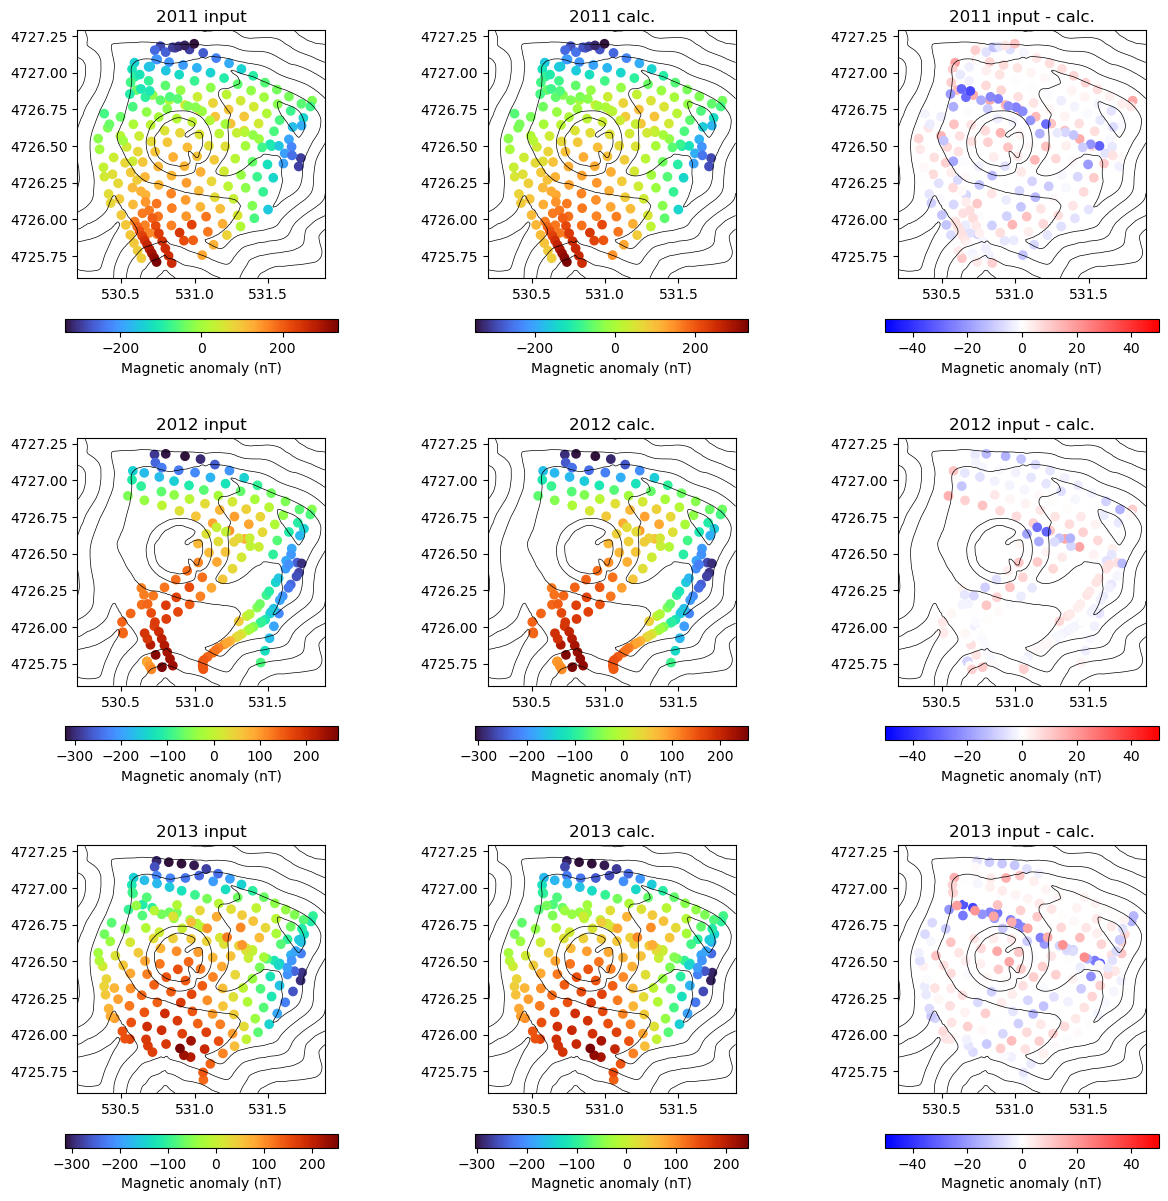

In [43]:
# Data fitting

fig = plt.figure(figsize = (15, 15))


# 2011
ax = fig.add_subplot(331)
p = ax.scatter(xobs1_corr, 
               yobs1_corr, 
               c = fobs[:len(fobs1_mean)], 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2011 input")

ax = fig.add_subplot(332)
p = ax.scatter(xobs1_corr, 
               yobs1_corr, 
               c = X1_coarse.dot(betas1_all[num_opt_2] * w1_coarse), 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2011 calc.")

ax = fig.add_subplot(333)
p = ax.scatter(xobs1_corr, 
               yobs1_corr, 
               c = fobs[:len(fobs1_mean)] - X1_coarse.dot(betas1_all[num_opt_2] * w1_coarse), 
               cmap = "bwr"
              )
p.set_clim(-50, 50)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2011 input - calc.")


# ----------------------------------
# 2013
# ----------------------------------

ax = fig.add_subplot(334)
p = ax.scatter(xobs2_corr, 
               yobs2_corr, 
               c = fobs[len(fobs1_mean):len(fobs1_mean)+len(fobs2_mean)], 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2012 input")

ax = fig.add_subplot(335)
p = ax.scatter(xobs2_corr, 
               yobs2_corr, 
               c = X2_coarse.dot(betas2_all[num_opt_2] * w2_coarse), 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2012 calc.")

ax = fig.add_subplot(336)
p = ax.scatter(xobs2_corr, 
               yobs2_corr, 
               c = fobs[len(fobs1_mean):len(fobs1_mean)+len(fobs2_mean)] - X2_coarse.dot(betas2_all[num_opt_2] * w2_coarse), 
               cmap = "bwr"
              )
p.set_clim(-50, 50)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2012 input - calc.")



# ----------------------------------
# 2013
# ----------------------------------

ax = fig.add_subplot(337)
p = ax.scatter(xobs3_corr, 
               yobs3_corr, 
               c = fobs[len(fobs1_mean)+len(fobs2_mean):], 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2013 input")

ax = fig.add_subplot(338)
p = ax.scatter(xobs3_corr, 
               yobs3_corr, 
               c = X3_coarse.dot(betas3_all[num_opt_2] * w3_coarse), 
               cmap = "turbo"
              )
#p.set_clim(-600, 400)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2013 calc.")

ax = fig.add_subplot(339)
p = ax.scatter(xobs3_corr, 
               yobs3_corr, 
               c = fobs[len(fobs1_mean)+len(fobs2_mean):] - X3_coarse.dot(betas3_all[num_opt_2] * w3_coarse), 
               cmap = "bwr"
              )
p.set_clim(-50, 50)
plt.colorbar(p, orientation = "horizontal", pad = 0.12, label = "Magnetic anomaly (nT)", shrink = 0.8)
ax.tricontour(xtopo, ytopo, ztopo, colors = "k", linewidths = 0.5)
ax.set_aspect("equal")
ax.set_title("2013 input - calc.")


plt.savefig("1006_data_input_and_calc-3.png", dpi = 600, bbox_inches = "tight")

In [49]:
def calc_rms_misfit(f, K, beta):
    return np.sqrt(np.linalg.norm(f - K@beta, ord=2)**2 / len(f))

In [53]:
print(
    calc_rms_misfit(fobs[:len(fobs1_mean)], X1_coarse, (betas1_all[num_opt_2] * w1_coarse)),
    calc_rms_misfit(fobs[len(fobs1_mean):len(fobs1_mean)+len(fobs2_mean)], X2_coarse, (betas2_all[num_opt_2] * w2_coarse)), 
    calc_rms_misfit(fobs[len(fobs1_mean)+len(fobs2_mean):], X3_coarse, (betas3_all[num_opt_2] * w3_coarse))
)

9.76347120203544 7.1163264114647555 10.44451468697446
